# Milestone 04 — Baseline Modeling & Evaluation Framework

## Purpose

This milestone establishes baseline fraud-detection models and a reusable evaluation framework before developing the PyTorch neural network.

The purpose of the baseline models is not simply to maximize performance. They provide reference points that help determine whether later deep-learning models actually add value.

## Locked Data Policy

The chronological split from Milestone 02 remains unchanged:

- Train: months 0–5
- Validation: month 6
- Test: month 7

The month-7 test partition remains sealed until Milestone 07.

All preprocessing must use the train-fitted pipeline established in Milestone 03.

No model-selection, threshold-selection, or tuning decision may use the test set.

## Primary Evaluation Metric

The primary model-comparison metric is:

**PR-AUC (Average Precision)**

PR-AUC is emphasized because fraud represents approximately 1% of the observations, making accuracy a poor primary metric.

## Additional Evaluation Metrics

The evaluation framework will also track:

- Precision
- Recall
- F1 score
- ROC-AUC
- Confusion matrix
- False positives
- False negatives

Probability-based models will also retain predicted probabilities for later:

- threshold optimization
- calibration analysis
- business-cost analysis
- error analysis

## Initial Baseline Strategy

Milestone 04 will begin with three levels of comparison:

1. **Dummy baseline**
   - Establishes a minimum reference point.
   - Shows how a trivial classifier behaves on the imbalanced dataset.

2. **Logistic Regression**
   - Provides an interpretable linear baseline.
   - Useful for determining how much signal can be captured without nonlinear interactions.

3. **Tree-based baseline**
   - Provides a nonlinear reference model.
   - Allows comparison with both logistic regression and the later neural network.

## Imbalance Policy

The original class distribution will initially be preserved.

Class weighting, oversampling, undersampling, and other imbalance strategies will be treated as separate experiments rather than silently changing the training distribution.

## Test-Set Discipline

The test set will not be used in this milestone.

Model comparison and development decisions will be based only on training and validation data.

Final test evaluation remains reserved for Milestone 07.

### Add the reproducible setup/import cell

In [ ]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    log_loss,
)

# Resolve repository root whether the notebook starts
# from the repository root or from /notebooks.
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Base.csv"
SPLIT_CONFIG_PATH = PROJECT_ROOT / "configs" / "split_config.json"
PREPROCESSING_CONFIG_PATH = (
    PROJECT_ROOT / "configs" / "preprocessing_config.json"
)

assert RAW_DATA_PATH.exists(), f"Missing raw dataset: {RAW_DATA_PATH}"
assert SPLIT_CONFIG_PATH.exists(), f"Missing split config: {SPLIT_CONFIG_PATH}"
assert PREPROCESSING_CONFIG_PATH.exists(), (
    f"Missing preprocessing config: {PREPROCESSING_CONFIG_PATH}"
)

print("Project root:", PROJECT_ROOT)
print("Raw dataset exists:", RAW_DATA_PATH.exists())
print("Split config exists:", SPLIT_CONFIG_PATH.exists())
print("Preprocessing config exists:", PREPROCESSING_CONFIG_PATH.exists())
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("scikit-learn version:", sklearn.__version__)

Project root: C:\Users\vrber\ML_Projects\bank-account-fraud-dl-mlops
Raw dataset exists: True
Split config exists: True
Preprocessing config exists: True
NumPy version: 2.4.6
Pandas version: 3.0.6
scikit-learn version: 1.9.1


### Verify the reusable split and preprocessing APIs

In [2]:
import inspect

from src.data import splitting
from src.features import preprocessing

print("Split functions:")
print("assign_split:", inspect.signature(splitting.assign_split))

print("\nPreprocessing functions:")
print(
    "load_preprocessing_config:",
    inspect.signature(preprocessing.load_preprocessing_config),
)
print(
    "prepare_model_features:",
    inspect.signature(preprocessing.prepare_model_features),
)
print(
    "build_preprocessor:",
    inspect.signature(preprocessing.build_preprocessor),
)

Split functions:
assign_split: (df, config=None)

Preprocessing functions:
load_preprocessing_config: (config_path=WindowsPath('C:/Users/vrber/ML_Projects/bank-account-fraud-dl-mlops/configs/preprocessing_config.json'))
prepare_model_features: (dataframe, config=None)
build_preprocessor: (config=None)


## Reusable Split and Preprocessing APIs Decision Summary
I separated configuration, reusable preprocessing logic, and experimentation notebooks. The notebooks call a small set of reusable Python APIs for splitting and preprocessing instead of reimplementing those rules. That reduces code duplication, helps prevent train-serving skew, and makes the pipeline easier to test and deploy.

### Load the locked configuration files

In [3]:
import json

with open(SPLIT_CONFIG_PATH, "r", encoding="utf-8") as f:
    split_config = json.load(f)

preprocessing_config = preprocessing.load_preprocessing_config(
    PREPROCESSING_CONFIG_PATH
)

print("Split config:")
print(split_config)

print("\nPreprocessing config version:")
print(preprocessing_config["version"])

print("\nTarget column:")
print(preprocessing_config["target_column"])

print("\nTest sealed until milestone:")
print(preprocessing_config["test_split_sealed_until_milestone"])

Split config:
{'version': '1.0', 'dataset': 'Base.csv', 'target': 'fraud_bool', 'temporal_field': 'month', 'strategy': 'chronological', 'train': {'months': [0, 1, 2, 3, 4, 5], 'rule': 'month <= 5', 'records': 794989, 'fraud_cases': 8151}, 'validation': {'months': [6], 'rule': 'month == 6', 'records': 108168, 'fraud_cases': 1450}, 'test': {'months': [7], 'rule': 'month == 7', 'records': 96843, 'fraud_cases': 1428, 'sealed': True}, 'month_used_as_model_feature_initially': False}

Preprocessing config version:
1.0

Target column:
fraud_bool

Test sealed until milestone:
7


### Load the raw dataset without touching the sealed test outcomes

In [4]:
df = pd.read_csv(RAW_DATA_PATH)

print("Dataset shape:", df.shape)
print("Column count:", len(df.columns))
print("Target present:", preprocessing_config["target_column"] in df.columns)
print("Temporal field present:", split_config["temporal_field"] in df.columns)

Dataset shape: (1000000, 32)
Column count: 32
Target present: True
Temporal field present: True


### Apply the locked chronological split

In [5]:
split_labels = splitting.assign_split(
    df,
    config=split_config,
)

print("Split counts:")
print(split_labels.value_counts())

print("\nMissing split assignments:")
print(split_labels.isna().sum())

Split counts:
split
train         794989
validation    108168
test           96843
Name: count, dtype: int64

Missing split assignments:
0


### Materialize only the development partitions

In [6]:
train_df = (
    df.loc[split_labels.eq("train")]
    .copy()
)

validation_df = (
    df.loc[split_labels.eq("validation")]
    .copy()
)

print("Train shape:", train_df.shape)
print("Validation shape:", validation_df.shape)

print(
    "Development rows:",
    len(train_df) + len(validation_df),
)

print(
    "Sealed test rows:",
    int(split_labels.eq("test").sum()),
)

Train shape: (794989, 32)
Validation shape: (108168, 32)
Development rows: 903157
Sealed test rows: 96843


### Prepare train and validation features using the reusable API

In [7]:
TARGET = preprocessing_config["target_column"]

train_features = preprocessing.prepare_model_features(
    train_df,
    preprocessing_config,
)

validation_features = preprocessing.prepare_model_features(
    validation_df,
    preprocessing_config,
)

y_train = train_df[TARGET].to_numpy(dtype=np.int64)
y_validation = validation_df[TARGET].to_numpy(dtype=np.int64)

print("Train features:", train_features.shape)
print("Validation features:", validation_features.shape)

print("Train target:", y_train.shape)
print("Validation target:", y_validation.shape)

print("Target excluded from train features:", TARGET not in train_features.columns)
print(
    "Feature columns identical:",
    train_features.columns.equals(validation_features.columns),
)

print("Train fraud cases:", int(y_train.sum()))
print("Validation fraud cases:", int(y_validation.sum()))

Train features: (794989, 34)
Validation features: (108168, 34)
Train target: (794989,)
Validation target: (108168,)
Target excluded from train features: True
Feature columns identical: True
Train fraud cases: 8151
Validation fraud cases: 1450


### Fit the preprocessing pipeline on training data only

In [8]:
preprocessor = preprocessing.build_preprocessor(
    preprocessing_config
)

# Learn scaling statistics and categorical vocabularies
# from TRAINING DATA ONLY.
preprocessor.fit(train_features)

X_train = preprocessor.transform(
    train_features
)

X_validation = preprocessor.transform(
    validation_features
)

processed_feature_names = (
    preprocessor.get_feature_names_out()
)

print("X_train shape:", X_train.shape)
print("X_validation shape:", X_validation.shape)

print("X_train dtype:", X_train.dtype)
print("X_validation dtype:", X_validation.dtype)

print("Processed feature count:", len(processed_feature_names))

print("Train values finite:", np.isfinite(X_train).all())
print(
    "Validation values finite:",
    np.isfinite(X_validation).all(),
)

print(
    "Same number of rows as targets:",
    X_train.shape[0] == y_train.shape[0]
    and X_validation.shape[0] == y_validation.shape[0],
)

X_train shape: (794989, 55)
X_validation shape: (108168, 55)
X_train dtype: float32
X_validation dtype: float32
Processed feature count: 55
Train values finite: True
Validation values finite: True
Same number of rows as targets: True


### Create the reusable baseline evaluation function

In [ ]:
def evaluate_binary_classifier(
    model_name,
    y_true,
    y_probability,
    threshold=0.50,
):
    """
    Evaluate a binary classifier from its positive-class probabilities.

    PR-AUC / Average Precision and ROC-AUC are threshold-independent.
    Precision, recall, F1, and the confusion matrix use the supplied threshold.
    """

    y_probability = np.asarray(y_probability)
    y_true = np.asarray(y_true)

    if y_probability.shape[0] != y_true.shape[0]:
        raise ValueError(
            "y_true and y_probability must contain the same number of rows."
        )

    if not np.isfinite(y_probability).all():
        raise ValueError(
            "Predicted probabilities contain non-finite values."
        )

    if not 0.0 <= threshold <= 1.0:
        raise ValueError(
            "threshold must be between 0 and 1."
        )

    y_pred = (
        y_probability >= threshold
    ).astype(np.int64)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1],
    ).ravel()

    results = {
        "model": model_name,
        "threshold": threshold,
        "pr_auc": average_precision_score(
            y_true,
            y_probability,
        ),
        "roc_auc": roc_auc_score(
            y_true,
            y_probability,
        ),
        "log_loss": log_loss(
            y_true,
            y_probability,
        ),
        "precision": precision_score(
            y_true,
            y_pred,
            zero_division=0,
        ),
        "recall": recall_score(
            y_true,
            y_pred,
            zero_division=0,
        ),
        "f1": f1_score(
            y_true,
            y_pred,
            zero_division=0,
        ),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
        "actual_positive_rate": float(
            np.mean(y_true)
        ),
        "predicted_positive_rate": float(
            np.mean(y_pred)
        ),
    }

    return results


print("Evaluation function defined successfully.")

Evaluation function defined successfully.


## Reusable Baseline Evaluation Function Decision Summary
This prevents us from changing the scoring rules depending on which model we are looking at. That does not mean 0.50 will be our final fraud threshold. We will optimize the business decision threshold later. In Milestone 04, 0.50 is simply a consistent reference point.

**One terminology detail worth remembering for interviews:** we are computing average_precision_score, which is commonly used as a PR-AUC summary for imbalanced classification. It is preferable here to accuracy because only about 1% of transactions are fraudulent.

### Train the dummy baseline

In [10]:
dummy_model = DummyClassifier(
    strategy="prior"
)

dummy_model.fit(
    X_train,
    y_train,
)

dummy_validation_probability = (
    dummy_model.predict_proba(X_validation)[:, 1]
)

dummy_results = evaluate_binary_classifier(
    model_name="DummyClassifier_prior",
    y_true=y_validation,
    y_probability=dummy_validation_probability,
    threshold=0.50,
)

dummy_results_df = pd.DataFrame(
    [dummy_results]
)

display(dummy_results_df.T)

,0
model,DummyClassifier_prior
threshold,0.5
pr_auc,0.013405
roc_auc,0.5
precision,0.0
recall,0.0
f1,0.0
tn,106718
fp,0
fn,1450


#### **What strategy="prior" means**
The dummy model learns only the class distribution from the training data.
Because fraud is rare, every validation observation will receive essentially the same fraud probability—approximately the training fraud rate.

### Train the unweighted Logistic Regression baseline

In [11]:
import time

logistic_model = LogisticRegression(
    solver="lbfgs",
    max_iter=1000,
)

start_time = time.perf_counter()

logistic_model.fit(
    X_train,
    y_train,
)

logistic_fit_seconds = (
    time.perf_counter() - start_time
)

logistic_validation_probability = (
    logistic_model.predict_proba(X_validation)[:, 1]
)

logistic_results = evaluate_binary_classifier(
    model_name="LogisticRegression_unweighted",
    y_true=y_validation,
    y_probability=logistic_validation_probability,
    threshold=0.50,
)

logistic_results["fit_seconds"] = (
    logistic_fit_seconds
)

logistic_results["iterations"] = int(
    logistic_model.n_iter_[0]
)

logistic_results_df = pd.DataFrame(
    [logistic_results]
)

display(logistic_results_df.T)

,0
model,LogisticRegression_unweighted
threshold,0.5
pr_auc,0.154819
roc_auc,0.881547
precision,0.461538
recall,0.004138
f1,0.008202
tn,106711
fp,7
fn,1444


### Train the nonlinear tree baseline

### **Why HistGradientBoostingClassifier?**
It gives us a strong nonlinear baseline without the memory and training cost of starting with a very large Random Forest.

It can learn relationships such as:

- feature A is high
- AND feature B is low
- AND category C is present
- → higher fraud risk

Logistic Regression cannot naturally capture those kinds of interactions unless we explicitly engineer them.


In [12]:
tree_model = HistGradientBoostingClassifier(
    learning_rate=0.10,
    max_iter=100,
    max_leaf_nodes=31,
    early_stopping=False,
    random_state=42,
)

start_time = time.perf_counter()

tree_model.fit(
    X_train,
    y_train,
)

tree_fit_seconds = (
    time.perf_counter() - start_time
)

tree_validation_probability = (
    tree_model.predict_proba(X_validation)[:, 1]
)

tree_results = evaluate_binary_classifier(
    model_name="HistGradientBoosting_unweighted",
    y_true=y_validation,
    y_probability=tree_validation_probability,
    threshold=0.50,
)

tree_results["fit_seconds"] = (
    tree_fit_seconds
)

tree_results["iterations"] = (
    tree_model.n_iter_
)

tree_results_df = pd.DataFrame(
    [tree_results]
)

display(tree_results_df.T)

,0
model,HistGradientBoosting_unweighted
threshold,0.5
pr_auc,0.166961
roc_auc,0.887977
precision,0.450893
recall,0.069655
f1,0.120669
tn,106595
fp,123
fn,1349


## Nonlinear Tree Baseline Summary
The nonlinear baseline improved on Logistic Regression, but only modestly on the threshold-independent metrics:
Dummy PR-AUC:      0.013405
Logistic PR-AUC:   0.154819
HistGradient PR-AUC: 0.166961

The tree model also has the best ROC-AUC so far at 0.887977. At the temporary 0.50 threshold, it identifies 101 fraud cases compared with only 6 for Logistic Regression, while still missing 1,349 fraud cases. That reinforces an important lesson: the model can rank risk reasonably well while 0.50 remains a poor operating threshold for this use case.
Also note that the tree took about 79 seconds versus about 16 seconds for Logistic Regression. So we are already seeing a performance-versus-compute tradeoff that will matter when we compare the later neural network.

### Build the first baseline comparison table

In [13]:
baseline_results = pd.DataFrame([
    dummy_results,
    logistic_results,
    tree_results,
])

comparison_columns = [
    "model",
    "pr_auc",
    "roc_auc",
    "precision",
    "recall",
    "f1",
    "fp",
    "fn",
    "tp",
    "threshold",
]

baseline_comparison = (
    baseline_results[comparison_columns]
    .sort_values(
        by="pr_auc",
        ascending=False,
    )
    .reset_index(drop=True)
)

display(baseline_comparison)

,model,pr_auc,roc_auc,precision,recall,f1,fp,fn,tp,threshold
0,HistGradientBoosting_unweighted,0.166961,0.887977,0.450893,0.069655,0.120669,123,1349,101,0.5
1,LogisticRegression_unweighted,0.154819,0.881547,0.461538,0.004138,0.008202,7,1444,6,0.5
2,DummyClassifier_prior,0.013405,0.500000,0.000000,0.000000,0.000000,0,1450,0,0.5


### Plot the Precision-Recall curves

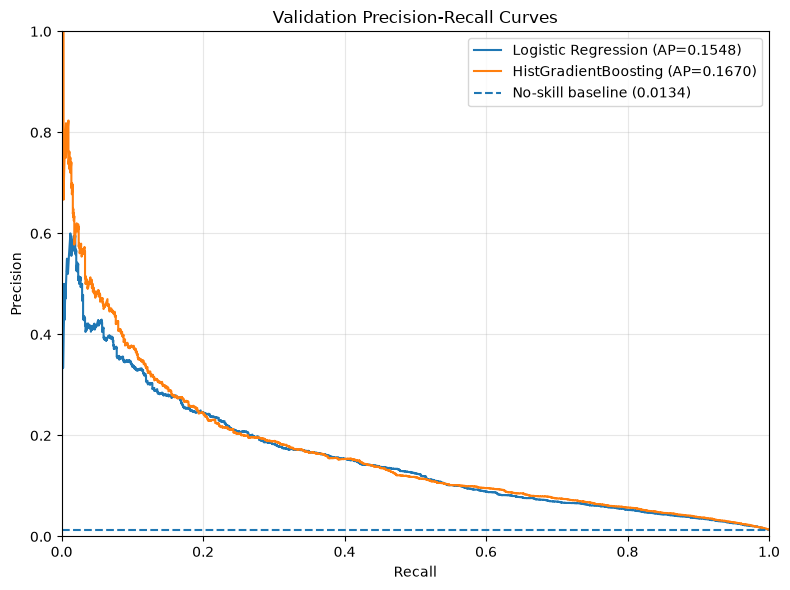

Figure saved to: C:\Users\vrber\ML_Projects\bank-account-fraud-dl-mlops\reports\figures\milestone_04_precision_recall_curve.png


In [14]:
from sklearn.metrics import precision_recall_curve

logistic_precision, logistic_recall, _ = precision_recall_curve(
    y_validation,
    logistic_validation_probability,
)

tree_precision, tree_recall, _ = precision_recall_curve(
    y_validation,
    tree_validation_probability,
)

validation_prevalence = y_validation.mean()

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    logistic_recall,
    logistic_precision,
    label=(
        "Logistic Regression "
        f"(AP={logistic_results['pr_auc']:.4f})"
    ),
)

ax.plot(
    tree_recall,
    tree_precision,
    label=(
        "HistGradientBoosting "
        f"(AP={tree_results['pr_auc']:.4f})"
    ),
)

ax.axhline(
    validation_prevalence,
    linestyle="--",
    label=(
        "No-skill baseline "
        f"({validation_prevalence:.4f})"
    ),
)

ax.set_title(
    "Validation Precision-Recall Curves"
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

ax.grid(alpha=0.3)
ax.legend()

figure_path = (
    PROJECT_ROOT
    / "reports"
    / "figures"
    / "milestone_04_precision_recall_curve.png"
)

fig.tight_layout()
fig.savefig(
    figure_path,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print("Figure saved to:", figure_path)

## Precision Recall Summary 
The chart tells us several useful things. Both real models stay far above the 1.34% no-skill baseline, confirming they have meaningful ranking power. HistGradientBoosting has the stronger overall Average Precision, 0.1670 versus 0.1548 for Logistic Regression, but the gap is modest rather than dramatic. The biggest advantage for HistGradientBoosting appears at relatively low recall, while the curves become much closer as recall increases. That suggests nonlinear feature interactions help, but they have not transformed the problem.
This is also why we should not say “HistGradientBoosting is 45% precise” without mentioning a threshold. The curve shows that precision changes considerably depending on how much fraud we try to capture.

### Plot the ROC Curves

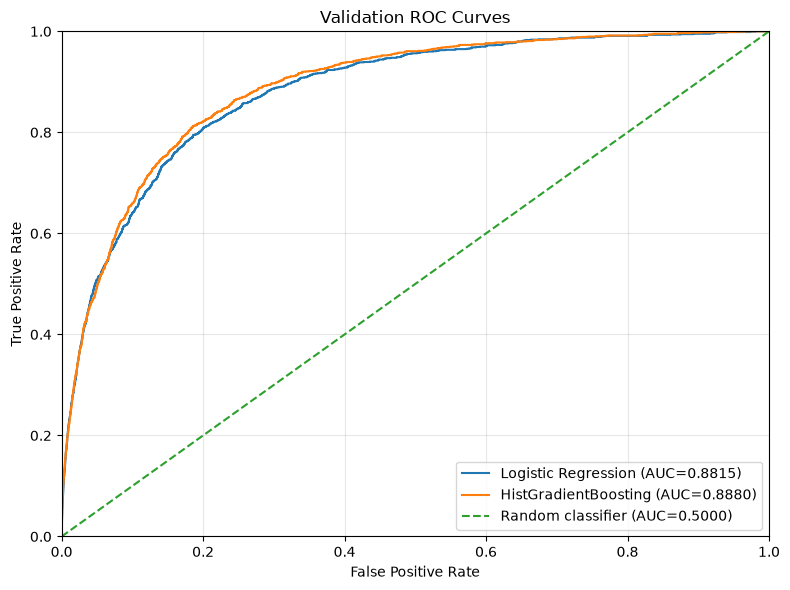

Figure saved to: C:\Users\vrber\ML_Projects\bank-account-fraud-dl-mlops\reports\figures\milestone_04_roc_curve.png


In [15]:
from sklearn.metrics import roc_curve

logistic_fpr, logistic_tpr, _ = roc_curve(
    y_validation,
    logistic_validation_probability,
)

tree_fpr, tree_tpr, _ = roc_curve(
    y_validation,
    tree_validation_probability,
)

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    logistic_fpr,
    logistic_tpr,
    label=(
        "Logistic Regression "
        f"(AUC={logistic_results['roc_auc']:.4f})"
    ),
)

ax.plot(
    tree_fpr,
    tree_tpr,
    label=(
        "HistGradientBoosting "
        f"(AUC={tree_results['roc_auc']:.4f})"
    ),
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier (AUC=0.5000)",
)

ax.set_title("Validation ROC Curves")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

ax.grid(alpha=0.3)
ax.legend()

roc_figure_path = (
    PROJECT_ROOT
    / "reports"
    / "figures"
    / "milestone_04_roc_curve.png"
)

fig.tight_layout()
fig.savefig(
    roc_figure_path,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print("Figure saved to:", roc_figure_path)

## ROC Decision Summary
Why we still include ROC-AUC
ROC-AUC answers a different question from PR-AUC:
- ROC-AUC: how well does the model rank a randomly chosen fraud case above a randomly chosen legitimate case?
- PR-AUC: when the model identifies cases as increasingly suspicious, how much precision can it retain while capturing fraud?

For this dataset, PR-AUC remains our primary metric because fraud is rare. ROC-AUC can look strong even when operational precision is still difficult.

The ROC curves reinforce the same conclusion as the Precision-Recall curves: both real models rank fraud substantially better than random, and HistGradientBoosting has only a small edge over Logistic Regression. 
- Logistic Regression ROC-AUC:  0.8815
- HistGradientBoosting ROC-AUC: 0.8880
- Random baseline:              0.5000 

That small gap is important. We should not conclude that the more complex model is automatically much better just because it is nonlinear. So far, Logistic Regression is surprisingly competitive while training much faster.